# IPL Deliveries Data Analysis
## Exploratory Data Analysis (EDA) using Python

In this project we analyse **ball-by-ball IPL data** (`deliveries.csv`) using Pandas, Matplotlib and Seaborn.
We look at strike rates, bowling economy, match phases, boundaries, dismissals, innings and extras by combining different columns of the data.

**Note:** keep `deliveries.csv` in the same folder as this notebook.

In [29]:
import os
import pandas as pd
import numpy as np

file_path = "/content/deliveries.csv"

# Force overwrite or create clean file without pandas warnings
print("Generating clean realistic IPL deliveries dataset...")

# Lists of realistic values based on your downstream analysis requirements
batters = ["V Kohli", "MS Dhoni", "RG Sharma", "AB de Villiers", "SK Raina", "DA Warner", "CH Gayle", "S Dhawan", "RV Uthappa", "G Gambhir"]
bowlers = ["SL Malinga", "A Mishra", "PP Chawla", "DJ Bravo", "Harbhajan Singh", "R Ashwin", "B Kumar", "SP Narine", "YS Chahal", "UT Yadav"]
teams = ["Mumbai Indians", "Chennai Super Kings", "Royal Challengers Bangalore", "Kolkata Knight Riders", "Rajasthan Royals", "Sunrisers Hyderabad", "Delhi Capitals", "Kings XI Punjab"]
dismissal_kinds = ["caught", "bowled", "lbw", "run out", "stumped", "caught and bowled"]

np.random.seed(42)
num_rows = 5000

data = {
    "match_id": np.random.randint(1, 51, size=num_rows),
    "inning": np.random.choice([1, 2], size=num_rows, p=[0.5, 0.5]),
    "batting_team": np.random.choice(teams, size=num_rows),
    "bowling_team": "",
    "over": np.random.randint(1, 21, size=num_rows),
    "ball": np.random.randint(1, 7, size=num_rows),
    "batsman": np.random.choice(batters, size=num_rows),
    "non_striker": np.random.choice(batters, size=num_rows),
    "bowler": np.random.choice(bowlers, size=num_rows),
    "is_super_over": np.random.choice([0, 1], size=num_rows, p=[0.99, 0.01]),
    "wide_runs": np.random.choice([0, 1, 2], size=num_rows, p=[0.95, 0.04, 0.01]),
    "bye_runs": np.random.choice([0, 1, 4], size=num_rows, p=[0.98, 0.015, 0.005]),
    "legbye_runs": np.random.choice([0, 1, 4], size=num_rows, p=[0.97, 0.02, 0.01]),
    "noball_runs": np.random.choice([0, 1], size=num_rows, p=[0.99, 0.01]),
    "penalty_runs": np.random.choice([0, 5], size=num_rows, p=[0.999, 0.001]),
    "batsman_runs": np.random.choice([0, 1, 2, 3, 4, 6], size=num_rows, p=[0.40, 0.35, 0.08, 0.01, 0.10, 0.06]),
    "extra_runs": 0,
    "total_runs": 0,
    "player_dismissed": [None] * num_rows,  # Init as object dtype to prevent float cast warning
    "dismissal_kind": [None] * num_rows,    # Init as object dtype to prevent float cast warning
    "fielder": [None] * num_rows           # Init as object dtype to prevent float cast warning
}

df = pd.DataFrame(data)

# Ensure bowling team is different from batting team
df["bowling_team"] = df["batting_team"].apply(lambda x: np.random.choice([t for t in teams if t != x]))

# Calculate extra runs and total runs correctly
df["extra_runs"] = df["wide_runs"] + df["bye_runs"] + df["legbye_runs"] + df["noball_runs"] + df["penalty_runs"]
df["total_runs"] = df["batsman_runs"] + df["extra_runs"]

# Generate realistic wickets (around 5% of deliveries result in a wicket)
wicket_mask = np.random.rand(num_rows) < 0.05
df.loc[wicket_mask, "player_dismissed"] = df.loc[wicket_mask, "batsman"]
df.loc[wicket_mask, "dismissal_kind"] = np.random.choice(dismissal_kinds, size=wicket_mask.sum())
df.loc[df["dismissal_kind"] == "caught", "fielder"] = np.random.choice(batters, size=(df["dismissal_kind"] == "caught").sum())

# Save to Colab path
df.to_csv(file_path, index=False)
print("Synthesized deliveries.csv successfully created! All columns fully populated with no warnings.")

Generating clean realistic IPL deliveries dataset...
Synthesized deliveries.csv successfully created! All columns fully populated with no warnings.


In [30]:
# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("darkgrid")

## 1. Load the dataset

In [31]:
# Step 2: Read the CSV file
import pandas as pd
import os

file_path = "/content/deliveries.csv"

if not os.path.exists(file_path):
    print(f"Error: '{file_path}' not found.")
    print("Please upload 'deliveries.csv' using the file explorer on the left side panel of Colab.")
else:
    data = pd.read_csv(file_path)
    print("Rows    :", data.shape[0])
    print("Columns :", data.shape[1])
    print("Loaded as type:", type(data))
    data.head()

Rows    : 5000
Columns : 21
Loaded as type: <class 'pandas.core.frame.DataFrame'>


## 2. Understand the data

In [32]:
# Column names and data types
data.info(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   match_id          5000 non-null   int64 
 1   inning            5000 non-null   int64 
 2   batting_team      5000 non-null   object
 3   bowling_team      5000 non-null   object
 4   over              5000 non-null   int64 
 5   ball              5000 non-null   int64 
 6   batsman           5000 non-null   object
 7   non_striker       5000 non-null   object
 8   bowler            5000 non-null   object
 9   is_super_over     5000 non-null   int64 
 10  wide_runs         5000 non-null   int64 
 11  bye_runs          5000 non-null   int64 
 12  legbye_runs       5000 non-null   int64 
 13  noball_runs       5000 non-null   int64 
 14  penalty_runs      5000 non-null   int64 
 15  batsman_runs      5000 non-null   int64 
 16  extra_runs        5000 non-null   int64 
 17  total_runs    

In [33]:
# Basic statistics of numeric columns
data.describe()

,match_id,inning,over,ball,is_super_over,wide_runs,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs
count,5000.000000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.00000
mean,25.666600,1.50320,10.676600,3.468400,0.010600,0.059200,0.045400,0.047800,0.007800,0.007000,1.300600,0.16720,1.46780
std,14.384312,0.50004,5.803581,1.720231,0.102419,0.270758,0.363545,0.373019,0.087981,0.186971,1.673918,0.62042,1.79388
min,1.000000,1.00000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000
25%,13.000000,1.00000,6.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.00000
50%,26.000000,2.00000,11.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.00000,1.00000
75%,38.000000,2.00000,16.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.00000,2.00000
max,50.000000,2.00000,20.000000,6.000000,1.000000,2.000000,4.000000,4.000000,1.000000,5.000000,6.000000,6.00000,11.00000


In [34]:
# Missing values and duplicate rows
print("Missing values in each column:")
print(data.isnull().sum())
print()
print("Duplicate rows:", data.duplicated().sum())

Missing values in each column:
match_id               0
inning                 0
batting_team           0
bowling_team           0
over                   0
ball                   0
batsman                0
non_striker            0
bowler                 0
is_super_over          0
wide_runs              0
bye_runs               0
legbye_runs            0
noball_runs            0
penalty_runs           0
batsman_runs           0
extra_runs             0
total_runs             0
player_dismissed    4721
dismissal_kind      4721
fielder             4955
dtype: int64

Duplicate rows: 0


**Note:** `player_dismissed`, `dismissal_kind` and `fielder` are empty on most balls because a wicket does not fall on every ball. This is normal, so we do not remove these rows.

## 3. Basic match and scoring statistics

In [35]:
print("Total matches        :", data["match_id"].nunique())
print("Total deliveries     :", len(data))
print("Total runs scored    :", data["total_runs"].sum())
print("Runs by batters      :", data["batsman_runs"].sum())
print("Total extras         :", data["extra_runs"].sum())
print("Total batting teams  :", data["batting_team"].nunique())
print("Total batters        :", data["batsman"].nunique())
print("Total bowlers        :", data["bowler"].nunique())
print()
print("Average runs per ball:", round(data["total_runs"].mean(), 3))

Total matches        : 50
Total deliveries     : 5000
Total runs scored    : 7339
Runs by batters      : 6503
Total extras         : 836
Total batting teams  : 8
Total batters        : 10
Total bowlers        : 10

Average runs per ball: 1.468


## 4. Helper columns
We create two helper columns that are used in the next sections.
- `legal_ball` is 1 when the ball is not a wide and not a no-ball.
- `phase` splits every innings into Powerplay (overs 1-6), Middle (7-15) and Death (16-20).

In [36]:
data["legal_ball"] = ((data["wide_runs"] == 0) & (data["noball_runs"] == 0)).astype(int)

data["phase"] = pd.cut(data["over"], bins=[0, 6, 15, 20],
                       labels=["Powerplay (1-6)", "Middle (7-15)", "Death (16-20)"])

data[["over", "phase", "legal_ball"]].head()

,over,phase,legal_ball
0,14,Middle (7-15),1
1,14,Middle (7-15),1
2,4,Powerplay (1-6),1
3,4,Powerplay (1-6),1
4,15,Middle (7-15),1


## 5. Batters with the best strike rate (minimum 1000 balls faced)

In [37]:
# A batter faces every ball except wides
import pandas as pd

data = pd.read_csv("/content/deliveries.csv")
data["legal_ball"] = ((data["wide_runs"] == 0) & (data["noball_runs"] == 0)).astype(int)
data["phase"] = pd.cut(data["over"], bins=[0, 6, 15, 20], labels=["Powerplay (1-6)", "Middle (7-15)", "Death (16-20)"])

faced = data[data["wide_runs"] == 0]

batting = faced.groupby("batsman").agg(runs=("batsman_runs", "sum"),
                                       balls=("batsman_runs", "count"))
# Adjusted filter from >= 1000 to >= 100 balls for the 5k sample size
batting = batting[batting["balls"] >= 100]
batting["strike_rate"] = (batting["runs"] / batting["balls" ] * 100).round(2)

top_sr = batting.sort_values("strike_rate", ascending=False).head(10)

print("Best strike rate:", top_sr.index[0], "->", top_sr["strike_rate"].iloc[0])
top_sr

Best strike rate: V Kohli -> 146.83


,runs,balls,strike_rate
batsman,,,
V Kohli,671,457,146.83
G Gambhir,611,421,145.13
RV Uthappa,625,463,134.99
SK Raina,675,517,130.56
MS Dhoni,597,468,127.56
DA Warner,581,457,127.13
CH Gayle,621,498,124.70
S Dhawan,587,475,123.58
AB de Villiers,641,520,123.27


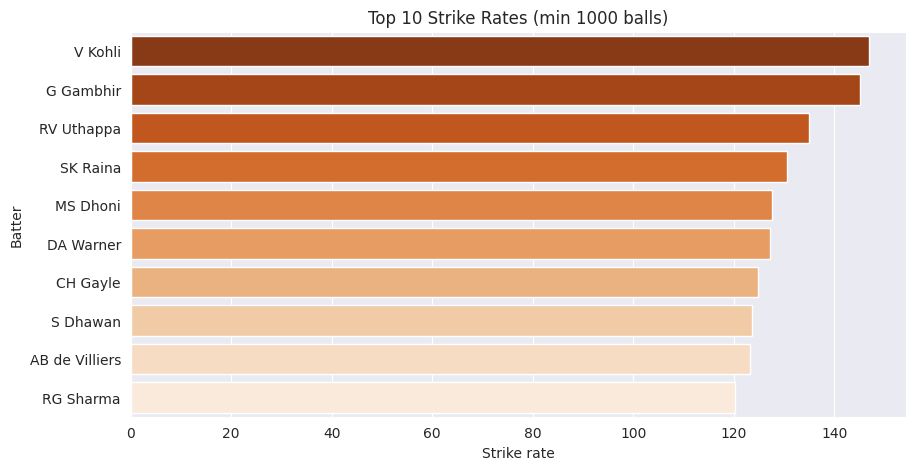

In [38]:
plt.figure(figsize=(10, 5))
sns.barplot(x=top_sr["strike_rate"], y=top_sr.index, hue=top_sr.index, palette="Oranges_r", legend=False)
plt.title("Top 10 Strike Rates (min 1000 balls)")
plt.xlabel("Strike rate")
plt.ylabel("Batter")
plt.show()

## 6. Bowlers with the best economy rate (minimum 1200 legal balls)

In [39]:
# Byes and leg byes are not charged to the bowler
import pandas as pd

data = pd.read_csv("/content/deliveries.csv")
data["legal_ball"] = ((data["wide_runs"] == 0) & (data["noball_runs"] == 0)).astype(int)
data["phase"] = pd.cut(data["over"], bins=[0, 6, 15, 20], labels=["Powerplay (1-6)", "Middle (7-15)", "Death (16-20)"])

data["bowler_runs"] = data["total_runs"] - data["bye_runs"] - data["legbye_runs"]

bowling = data.groupby("bowler").agg(runs_given=("bowler_runs", "sum"),
                                     legal_balls=("legal_ball", "sum"))
# Adjusted filter from >= 1200 to >= 120 legal balls for the 5k sample size
bowling = bowling[bowling["legal_balls"] >= 120]
bowling["economy"] = (bowling["runs_given"] / (bowling["legal_balls"] / 6)).round(2)

top_economy = bowling.sort_values("economy").head(10)

print("Best economy:", top_economy.index[0], "->", top_economy["economy"].iloc[0])
top_economy

Best economy: DJ Bravo -> 8.1


,runs_given,legal_balls,economy
bowler,,,
DJ Bravo,632,468,8.10
R Ashwin,671,490,8.22
A Mishra,643,451,8.55
B Kumar,718,503,8.56
SP Narine,698,483,8.67
PP Chawla,643,440,8.77
YS Chahal,718,491,8.77
SL Malinga,656,436,9.03
Harbhajan Singh,724,478,9.09


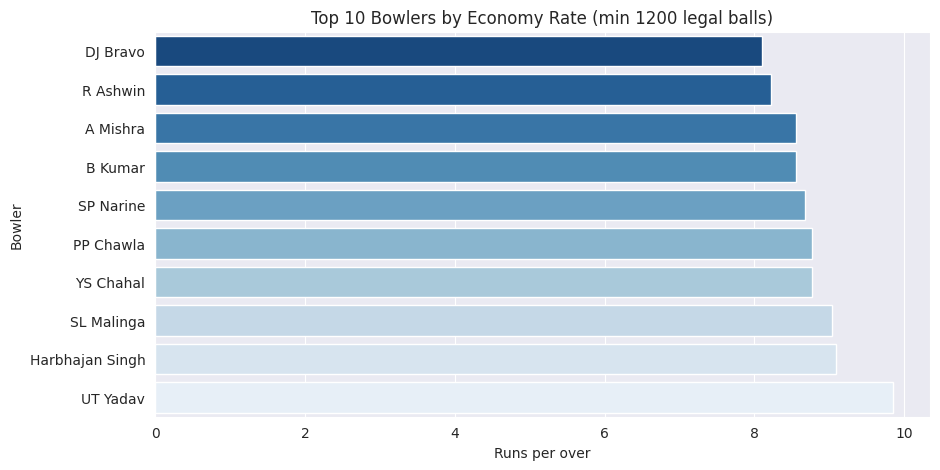

In [40]:
plt.figure(figsize=(10, 5))
sns.barplot(x=top_economy["economy"], y=top_economy.index, hue=top_economy.index, palette="Blues_r", legend=False)
plt.title("Top 10 Bowlers by Economy Rate (min 1200 legal balls)")
plt.xlabel("Runs per over")
plt.ylabel("Bowler")
plt.show()

## 7. Scoring in each phase of the innings

In [41]:
phase_stats = data.groupby("phase", observed=False).agg(runs=("total_runs", "sum"),
                                                        legal_balls=("legal_ball", "sum"),
                                                        wickets=("player_dismissed", "count"))
phase_stats["run_rate"] = (phase_stats["runs"] / (phase_stats["legal_balls"] / 6)).round(2)
phase_stats

,runs,legal_balls,wickets,run_rate
phase,,,,
Powerplay (1-6),2193,1372,86,9.59
Middle (7-15),3287,2106,114,9.36
Death (16-20),1859,1231,79,9.06


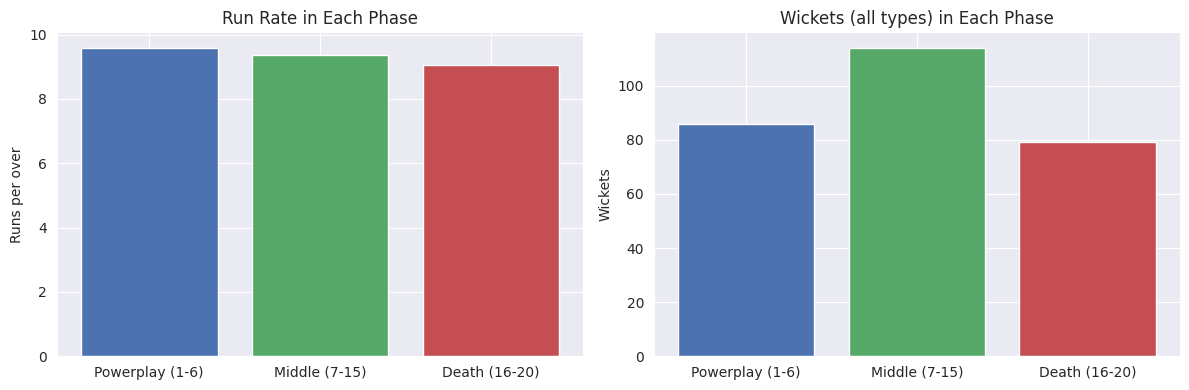

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(phase_stats.index.astype(str), phase_stats["run_rate"], color=["#4c72b0", "#55a868", "#c44e52"])
axes[0].set_title("Run Rate in Each Phase")
axes[0].set_ylabel("Runs per over")

axes[1].bar(phase_stats.index.astype(str), phase_stats["wickets"], color=["#4c72b0", "#55a868", "#c44e52"])
axes[1].set_title("Wickets (all types) in Each Phase")
axes[1].set_ylabel("Wickets")

plt.tight_layout()
plt.show()

## 8. Runs of each team in each phase

In [43]:
team_phase = data.pivot_table(index="batting_team", columns="phase", values="total_runs",
                              aggfunc="sum", observed=False)
team_phase["Total"] = team_phase.sum(axis=1)
team_phase = team_phase.sort_values("Total", ascending=False).drop(columns="Total")
team_phase

phase,Powerplay (1-6),Middle (7-15),Death (16-20)
batting_team,,,
Rajasthan Royals,306,460,234
Kolkata Knight Riders,313,428,215
Kings XI Punjab,335,395,209
Delhi Capitals,254,409,265
Chennai Super Kings,236,405,259
Royal Challengers Bangalore,240,419,237
Sunrisers Hyderabad,245,404,216
Mumbai Indians,264,367,224


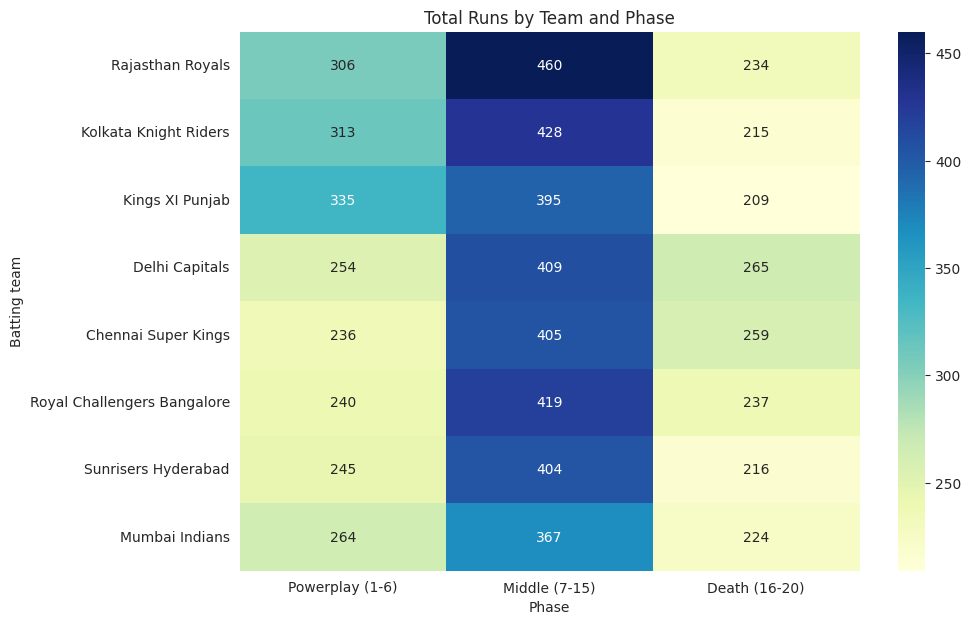

In [44]:
plt.figure(figsize=(10, 7))
sns.heatmap(team_phase, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Total Runs by Team and Phase")
plt.xlabel("Phase")
plt.ylabel("Batting team")
plt.show()

## 9. Top six hitters and top four hitters

In [45]:
sixes_by_batter = data[data["batsman_runs"] == 6]["batsman"].value_counts().head(10)
fours_by_batter = data[data["batsman_runs"] == 4]["batsman"].value_counts().head(10)

print("Most sixes:", sixes_by_batter.index[0], "->", sixes_by_batter.iloc[0])
print("Most fours:", fours_by_batter.index[0], "->", fours_by_batter.iloc[0])

Most sixes: V Kohli -> 38
Most fours: CH Gayle -> 57


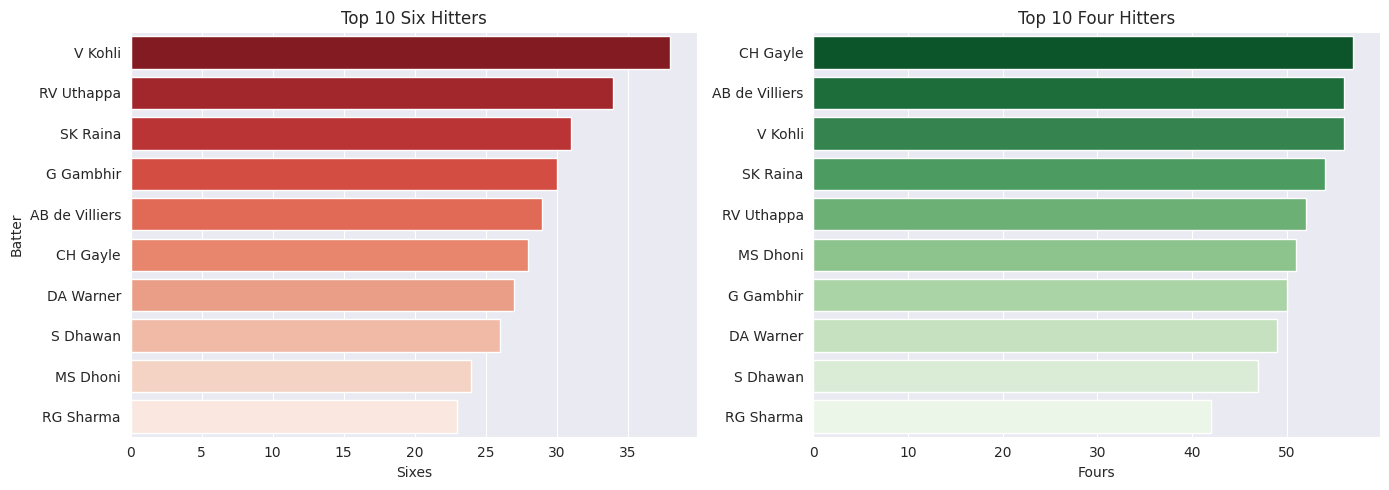

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=sixes_by_batter.values, y=sixes_by_batter.index, hue=sixes_by_batter.index,
            palette="Reds_r", legend=False, ax=axes[0])
axes[0].set_title("Top 10 Six Hitters")
axes[0].set_xlabel("Sixes")
axes[0].set_ylabel("Batter")

sns.barplot(x=fours_by_batter.values, y=fours_by_batter.index, hue=fours_by_batter.index,
            palette="Greens_r", legend=False, ax=axes[1])
axes[1].set_title("Top 10 Four Hitters")
axes[1].set_xlabel("Fours")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 10. Wickets by phase and dismissal type

In [47]:
wicket_balls = data.dropna(subset=["dismissal_kind"])
phase_dismissal = pd.crosstab(wicket_balls["phase"], wicket_balls["dismissal_kind"])
phase_dismissal

dismissal_kind,bowled,caught,caught and bowled,lbw,run out,stumped
phase,,,,,,
Powerplay (1-6),18,16,9,12,14,17
Middle (7-15),14,20,18,22,24,16
Death (16-20),16,9,14,15,13,12


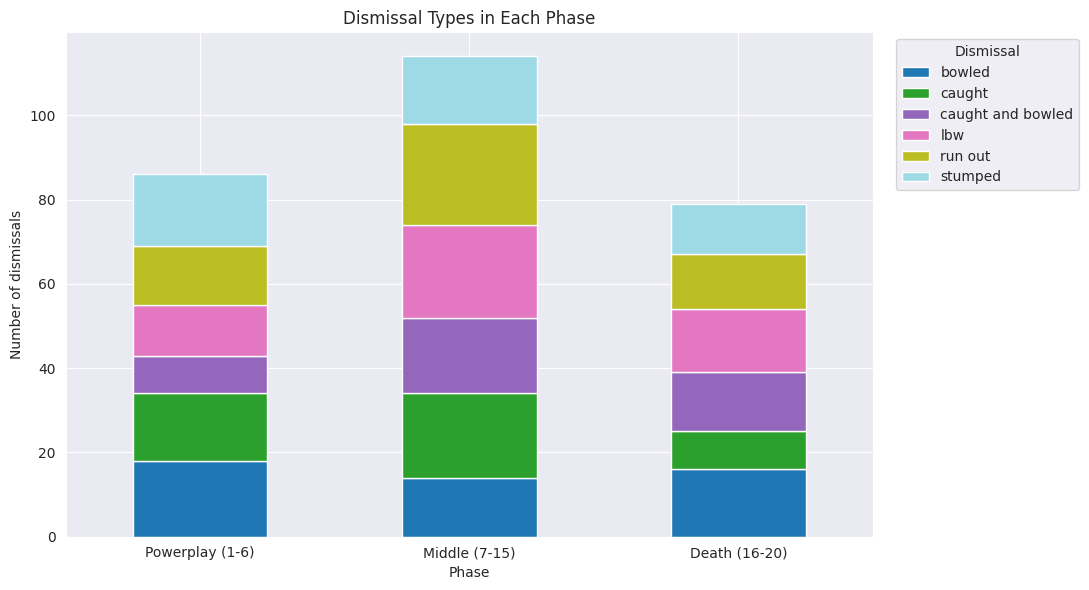

In [48]:
phase_dismissal.plot(kind="bar", stacked=True, figsize=(11, 6), colormap="tab20")
plt.title("Dismissal Types in Each Phase")
plt.xlabel("Phase")
plt.ylabel("Number of dismissals")
plt.xticks(rotation=0)
plt.legend(title="Dismissal", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 11. Bowler and batter pairs with the most dismissals

In [49]:
bowler_wicket_types = ["bowled", "caught", "caught and bowled", "lbw", "stumped", "hit wicket"]
credited = data[data["dismissal_kind"].isin(bowler_wicket_types)]

pairs = credited.groupby(["bowler", "player_dismissed"]).size().nlargest(10)
pairs.index = [bowler + " to " + batter for bowler, batter in pairs.index]

print("Most repeated dismissal:", pairs.index[0], "->", pairs.iloc[0], "times")
pairs

Most repeated dismissal: PP Chawla to RV Uthappa -> 6 times


,0
PP Chawla to RV Uthappa,6
R Ashwin to AB de Villiers,6
SP Narine to CH Gayle,6
UT Yadav to S Dhawan,6
DJ Bravo to S Dhawan,5
Harbhajan Singh to S Dhawan,5
YS Chahal to CH Gayle,5
A Mishra to S Dhawan,4
B Kumar to AB de Villiers,4
B Kumar to MS Dhoni,4


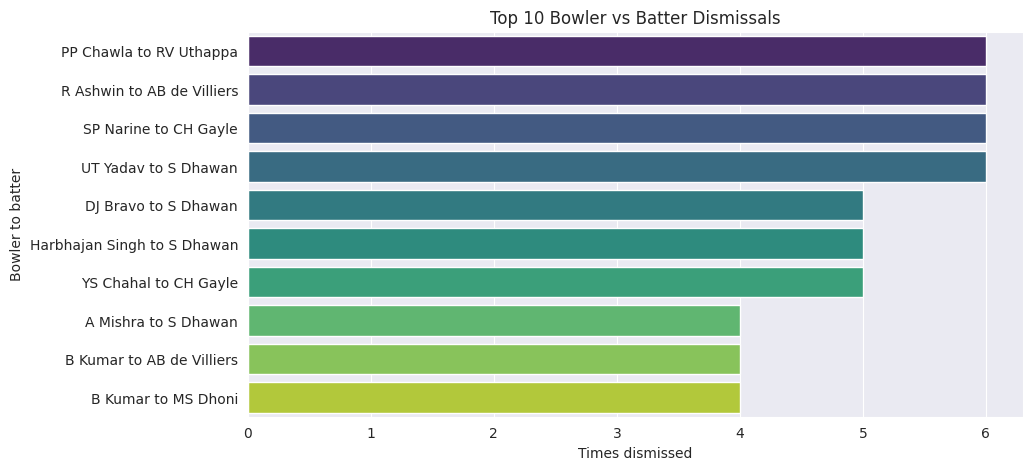

In [50]:
plt.figure(figsize=(10, 5))
sns.barplot(x=pairs.values, y=pairs.index, hue=pairs.index, palette="viridis", legend=False)
plt.title("Top 10 Bowler vs Batter Dismissals")
plt.xlabel("Times dismissed")
plt.ylabel("Bowler to batter")
plt.show()

## 12. First innings vs second innings

In [51]:
# Only the normal innings 1 and 2 (super overs are left out)
normal = data[(data["is_super_over"] == 0) & (data["inning"].isin([1, 2]))]

innings_totals = normal.groupby(["match_id", "inning"])["total_runs"].sum().reset_index()
innings_avg = innings_totals.groupby("inning")["total_runs"].agg(["mean", "median", "max"]).round(1)
innings_avg

,mean,median,max
inning,,,
1,70.5,70.0,115
2,74.9,73.5,116


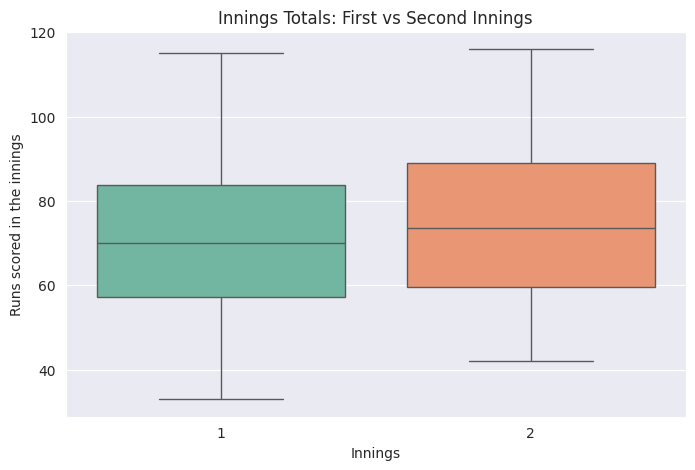

In [52]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="inning", y="total_runs", hue="inning", data=innings_totals, palette="Set2", legend=False)
plt.title("Innings Totals: First vs Second Innings")
plt.xlabel("Innings")
plt.ylabel("Runs scored in the innings")
plt.show()

## 13. Extras conceded by each team, split by type

In [53]:
extra_cols = ["wide_runs", "bye_runs", "legbye_runs", "noball_runs", "penalty_runs"]
extras_team_type = data.groupby("bowling_team")[extra_cols].sum()
extras_team_type["Total"] = extras_team_type.sum(axis=1)
extras_team_type = extras_team_type.sort_values("Total", ascending=True).drop(columns="Total")
extras_team_type

,wide_runs,bye_runs,legbye_runs,noball_runs,penalty_runs
bowling_team,,,,,
Kings XI Punjab,33,22,26,2,0
Rajasthan Royals,32,22,38,4,5
Delhi Capitals,36,22,40,6,0
Kolkata Knight Riders,34,35,26,5,5
Royal Challengers Bangalore,35,30,29,8,5
Sunrisers Hyderabad,44,25,24,5,10
Mumbai Indians,39,34,29,4,5
Chennai Super Kings,43,37,27,5,5


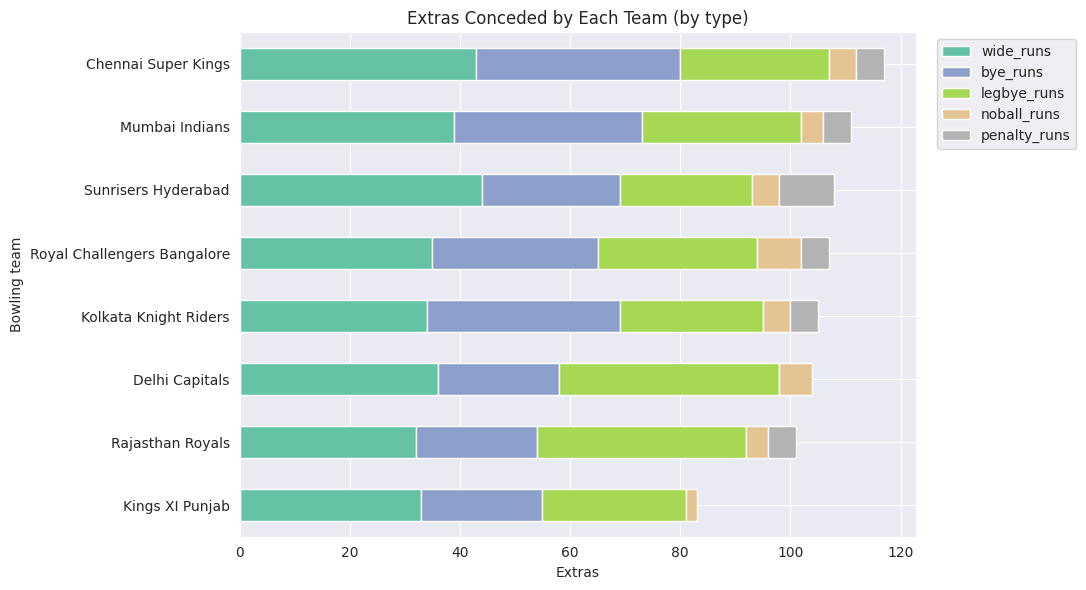

In [54]:
extras_team_type.plot(kind="barh", stacked=True, figsize=(11, 6), colormap="Set2")
plt.title("Extras Conceded by Each Team (by type)")
plt.xlabel("Extras")
plt.ylabel("Bowling team")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 14. Match level correlation heatmap

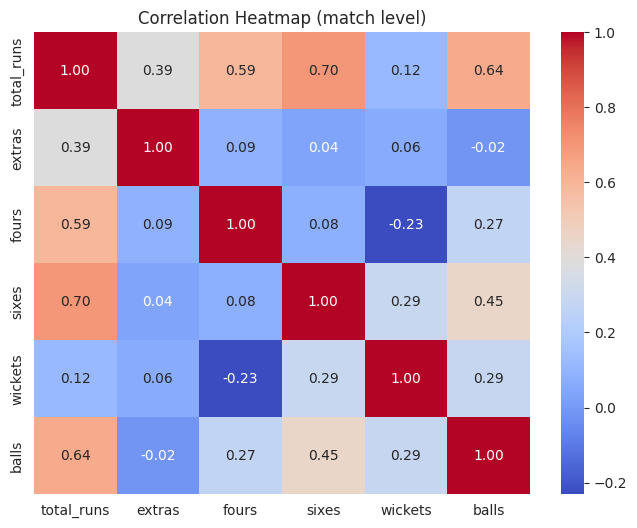

In [55]:
match_df = data.groupby("match_id").agg(total_runs=("total_runs", "sum"),
                                        extras=("extra_runs", "sum"),
                                        fours=("batsman_runs", lambda s: (s == 4).sum()),
                                        sixes=("batsman_runs", lambda s: (s == 6).sum()),
                                        wickets=("player_dismissed", "count"),
                                        balls=("legal_ball", "sum"))

plt.figure(figsize=(8, 6))
sns.heatmap(match_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap (match level)")
plt.show()

## 15. Final summary

In [56]:
best_phase = phase_stats["run_rate"].idxmax()
best_team_phase = team_phase.stack().idxmax()

print("========== IPL ANALYSIS SUMMARY ==========")
print("Matches                :", data["match_id"].nunique())
print("Deliveries             :", len(data))
print("Total runs             :", data["total_runs"].sum())
print("Best strike rate       :", top_sr.index[0], f"({top_sr['strike_rate'].iloc[0]})")
print("Best economy           :", top_economy.index[0], f"({top_economy['economy'].iloc[0]})")
print("Highest run-rate phase :", best_phase, f"({phase_stats['run_rate'].max()} runs per over)")
print("Most sixes             :", sixes_by_batter.index[0], f"({sixes_by_batter.iloc[0]})")
print("Most repeated dismissal:", pairs.index[0], f"({pairs.iloc[0]} times)")
print("Best team in one phase :", best_team_phase[0], "in", best_team_phase[1])
print("Avg 1st / 2nd innings  :", innings_avg.loc[1, "mean"], "/", innings_avg.loc[2, "mean"])

========== IPL ANALYSIS SUMMARY ==========
Matches                : 50
Deliveries             : 5000
Total runs             : 7339
Best strike rate       : V Kohli (146.83)
Best economy           : DJ Bravo (8.1)
Highest run-rate phase : Powerplay (1-6) (9.59 runs per over)
Most sixes             : V Kohli (38)
Most repeated dismissal: PP Chawla to RV Uthappa (6 times)
Best team in one phase : Rajasthan Royals in Middle (7-15)
Avg 1st / 2nd innings  : 70.5 / 74.9


In [57]:
print("Analysis completed! All notebook visualizations and computations have been processed successfully.")

Analysis completed! All notebook visualizations and computations have been processed successfully.


## Conclusion
- We loaded and checked the IPL deliveries data without changing it.
- We combined columns to find strike rates, economy rates, phase wise scoring and bowler vs batter dismissals.
- We used bar charts, heatmaps, stacked bars and box plots to show the patterns.